In [ ]:
from IPython.display import Markdown as md

### change to reflect your notebook
_nb_loc = "06_preprocessing/06g_tiling.ipynb"
_nb_title = "Creating image tiles from a larger image"

### no need to change any of this
_nb_safeloc = _nb_loc.replace('/', '%2F')
md("""
<table class="tfo-notebook-buttons" align="left">
  <td>
    <a target="_blank" href="https://console.cloud.google.com/ai-platform/notebooks/deploy-notebook?name={1}&url=https%3A%2F%2Fgithub.com%2FGoogleCloudPlatform%2Fpractical-ml-vision-book%2Fblob%2Fmaster%2F{2}&download_url=https%3A%2F%2Fgithub.com%2FGoogleCloudPlatform%2Fpractical-ml-vision-book%2Fraw%2Fmaster%2F{2}">
    <img src="https://raw.githubusercontent.com/GoogleCloudPlatform/practical-ml-vision-book/master/logo-cloud.png"/> Run in AI Platform Notebook</a>
  </td>
  </td>
  <td>
    <a target="_blank" href="https://colab.research.google.com/github/GoogleCloudPlatform/practical-ml-vision-book/blob/master/{0}">
    <img src="https://www.tensorflow.org/images/colab_logo_32px.png" />Run in Google Colab</a>
  </td>
  <td>
    <a target="_blank" href="https://github.com/GoogleCloudPlatform/practical-ml-vision-book/blob/master/{0}">
    <img src="https://www.tensorflow.org/images/GitHub-Mark-32px.png" />View source on GitHub</a>
  </td>
  <td>
    <a href="https://raw.githubusercontent.com/GoogleCloudPlatform/practical-ml-vision-book/master/{0}">
    <img src="https://www.tensorflow.org/images/download_logo_32px.png" />Download notebook</a>
  </td>
</table>
""".format(_nb_loc, _nb_title, _nb_safeloc))

# Creating image tiles from a larger image

In this notebook, we show how to build an input pipeline that tiles a large geospatial image.

## Enable GPU and set up helper functions

This notebook and pretty much every other notebook in this repository
will run faster if you are using a GPU.
On Colab:
- Navigate to Edit→Notebook Settings
- Select GPU from the Hardware Accelerator drop-down

On Cloud AI Platform Notebooks:
- Navigate to https://console.cloud.google.com/ai-platform/notebooks
- Create an instance with a GPU or select your instance and add a GPU

Next, we'll confirm that we can connect to the GPU with tensorflow:

In [ ]:
import tensorflow as tf
print(tf.version.VERSION)
device_name = tf.test.gpu_device_name()
if device_name != '/device:GPU:0':
  raise SystemError('GPU device not found')
print('Found GPU at: {}'.format(device_name))

## Input data

Read the input data

In [13]:
!gcloud storage cat gs://practical-ml-vision-book-data/images/california_fires.txt

{"fullimg": "gs://practical-ml-vision-book-data/images/california_fire1.jpg", "fires": [[88, 244], [118, 257], [118, 285], [160, 276], [296, 379]]}
{"fullimg": "gs://practical-ml-vision-book-data/images/california_fire2.jpg", "fires": [[84, 255], [90, 250], [118, 261], [119, 288], [152, 501], [160, 281], [296, 383]]}


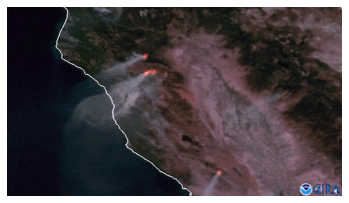

In [14]:
import matplotlib.pylab as plt
import numpy as np
import tensorflow as tf
import json

def read_jpeg(filename):
    img = tf.io.read_file(filename)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.convert_image_dtype(img, tf.float32)
    return img

fullimg = read_jpeg('gs://practical-ml-vision-book-data/images/california_fire1.jpg')
plt.imshow(fullimg);
plt.axis('off');

## Tiling the image

(1, 4, 8, 49152)
(4, 8, 128, 128, 3)


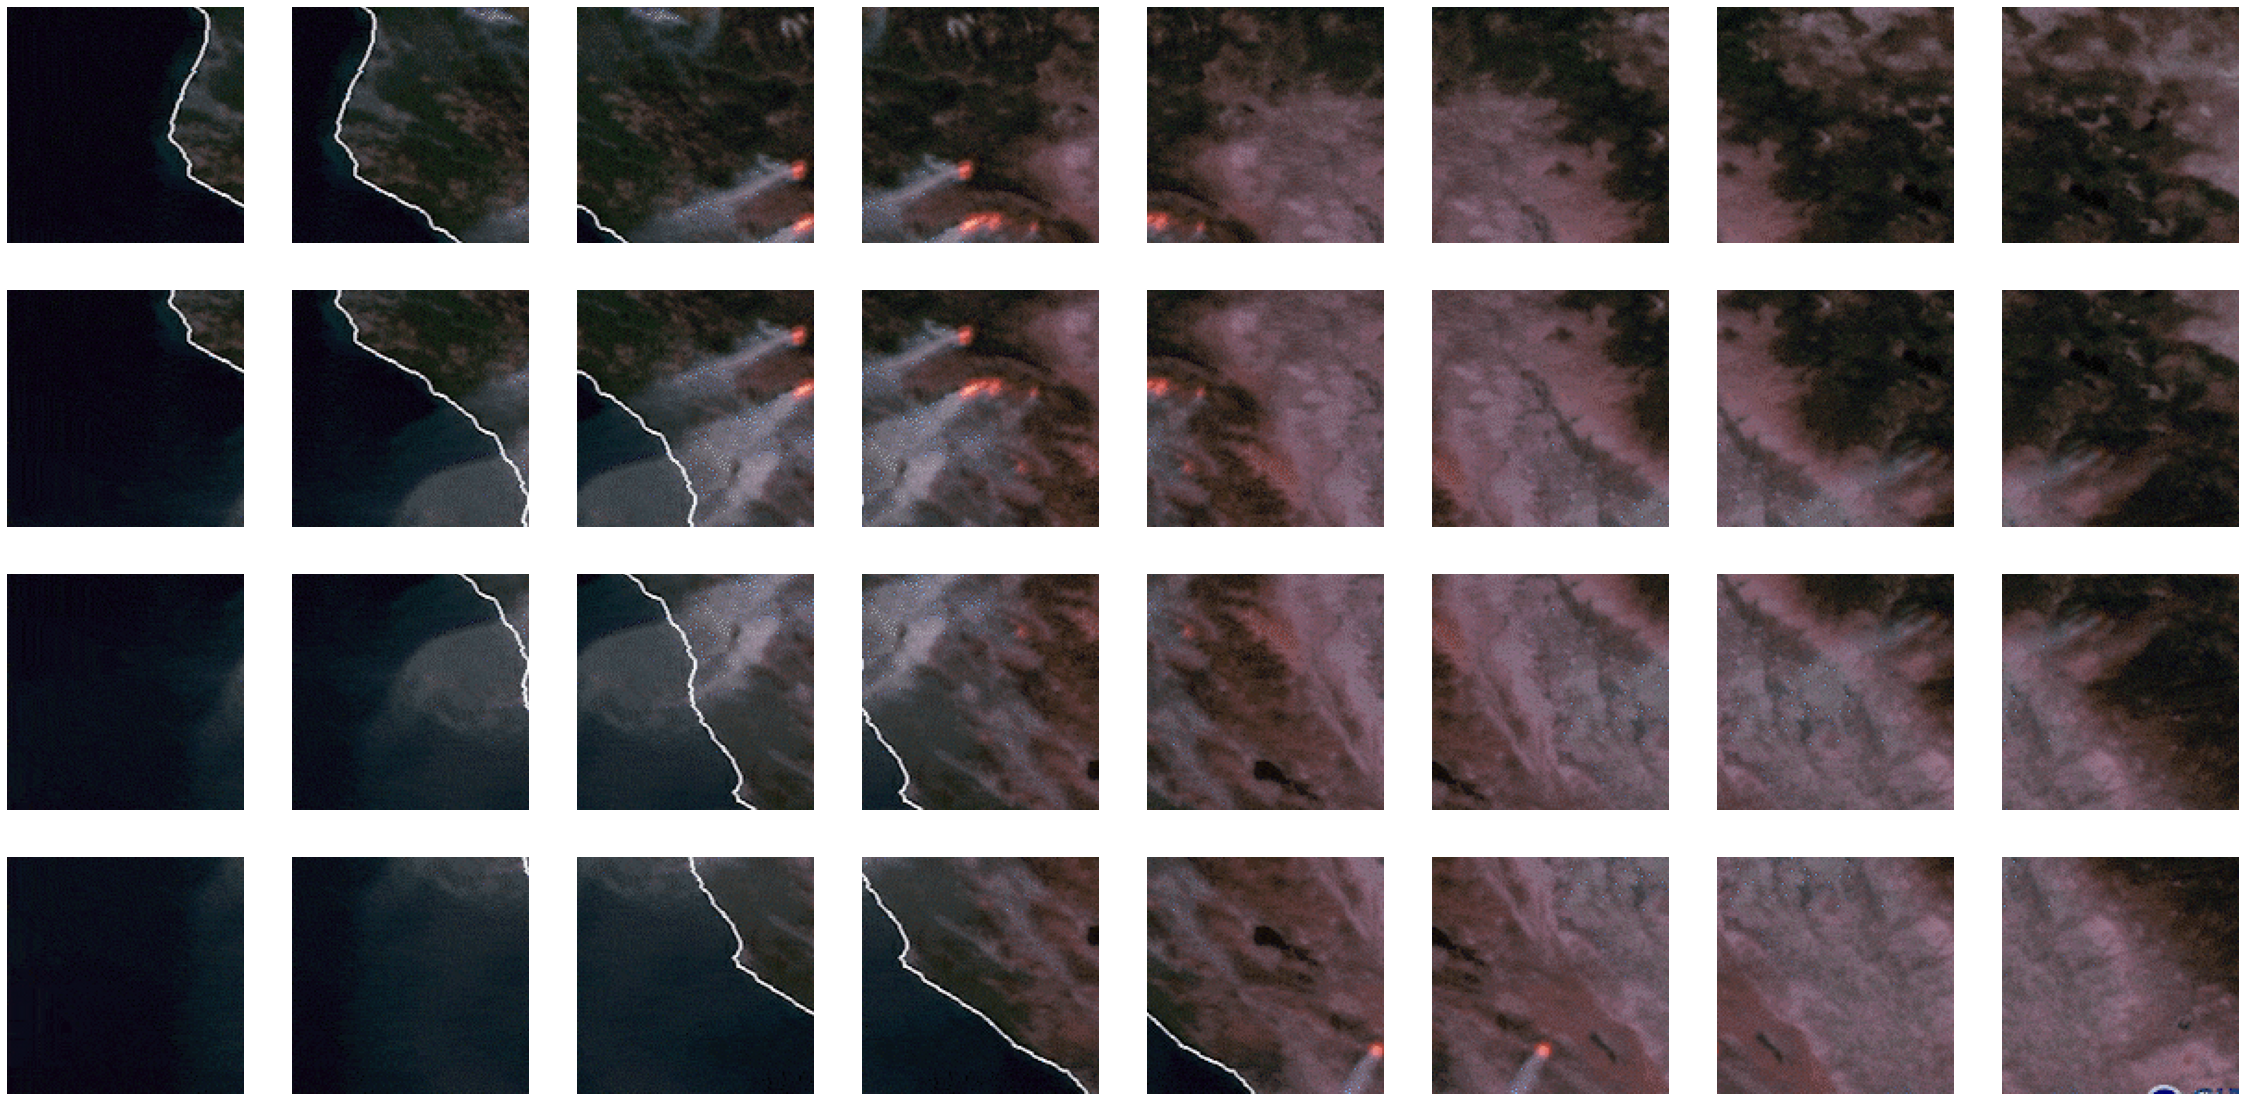

In [15]:
def tile_image(fullimg, CHANNELS=3, TILE_HT=128, TILE_WD=128):
    images = tf.expand_dims(fullimg, axis=0)
    tiles = tf.image.extract_patches(
        images=images,
        sizes=[1, TILE_HT, TILE_WD, 1],
        strides=[1, TILE_HT//2, TILE_WD//2, 1],
        rates=[1, 1, 1, 1],
        padding='VALID')
    print(tiles.shape)

    tiles = tf.squeeze(tiles, axis=0)
    nrows = tiles.shape[0]
    ncols = tiles.shape[1]
    tiles = tf.reshape(tiles, [nrows, ncols, TILE_HT, TILE_WD, CHANNELS])
    print(tiles.shape)
    return tiles

tiles = tile_image(fullimg)
nrows = tiles.shape[0]
ncols = tiles.shape[1]
f, ax = plt.subplots(nrows, ncols, figsize=(40,20))
for rowno in range(nrows):
    for colno in range(ncols):
        img = tiles[rowno][colno]
        ax[rowno, colno].imshow( tiles[rowno][colno].numpy() );
        ax[rowno, colno].axis('off')

## Getting the label for each tile

We take the fire locations, plot them on the image, tile the image, and then find the maximum pixel within each tile.
If the max pixel is 1.0, then the tile contains a fire.

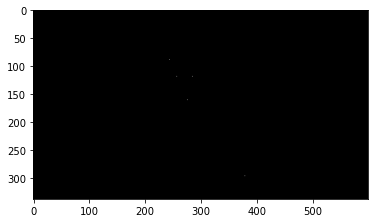

In [16]:
fire_locations = [[88, 244], [118, 257], [118, 285], [160, 276], [296, 379]]
fire_label = np.zeros((338, 600))
for loc in fire_locations:
    fire_label[loc[0]][loc[1]] = 1.0
plt.imshow(fire_label, cmap='gray');

In [17]:
labels = tf.expand_dims(fire_label, axis=-1)
print(labels.shape)
labels = tile_image(labels, 1)
labels = tf.reduce_max(labels, axis=[2, 3, 4])
print(labels)

(338, 600, 1)
(1, 4, 8, 16384)
(4, 8, 128, 128, 1)
tf.Tensor(
[[0. 0. 1. 1. 1. 0. 0. 0.]
 [0. 0. 1. 1. 1. 0. 0. 0.]
 [0. 0. 0. 1. 1. 0. 0. 0.]
 [0. 0. 0. 0. 1. 1. 0. 0.]], shape=(4, 8), dtype=float64)


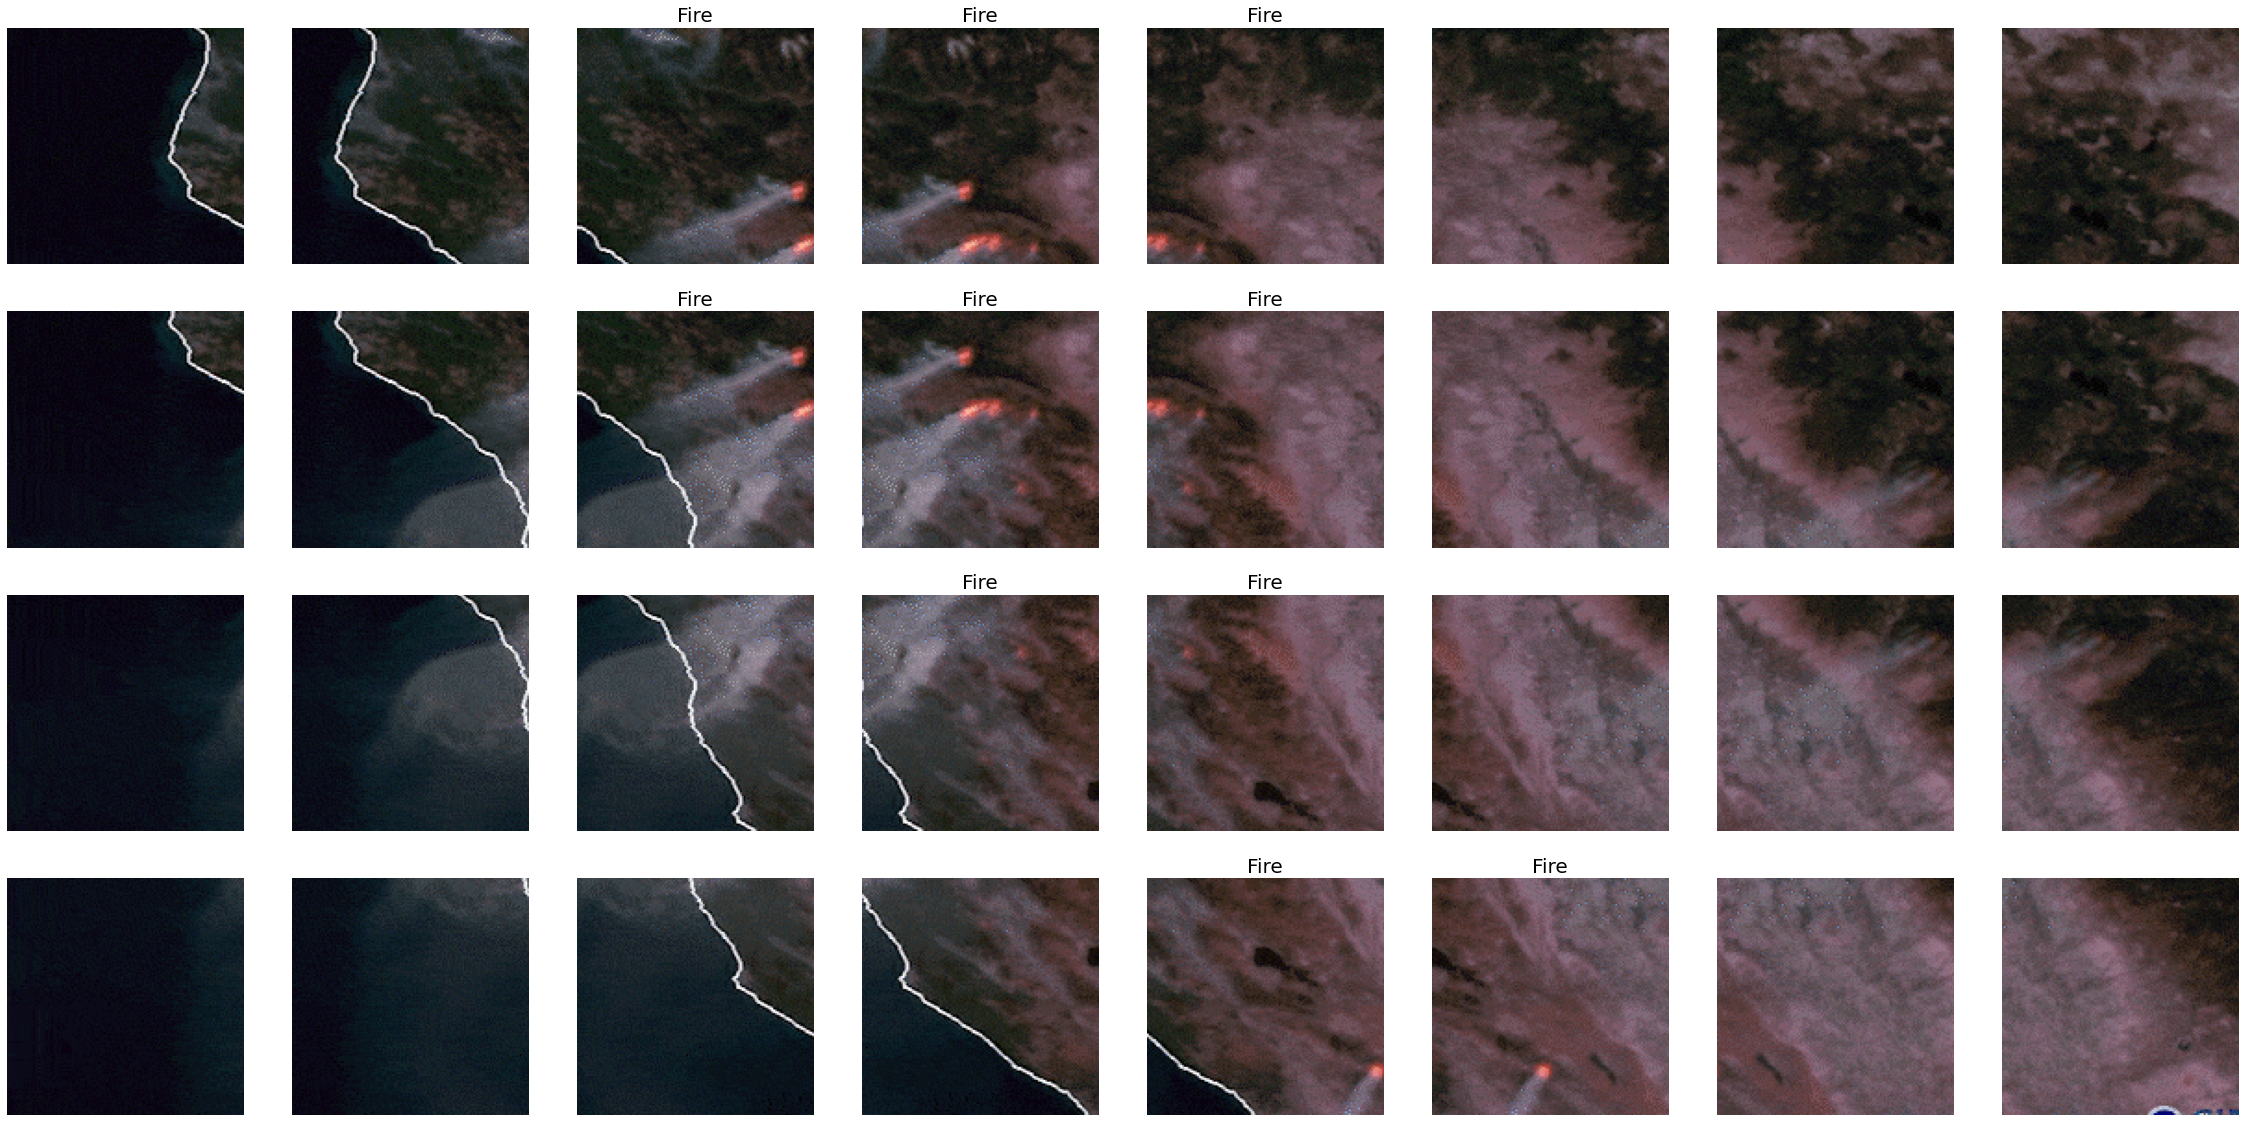

In [18]:
f, ax = plt.subplots(nrows, ncols, figsize=(40,20))
for rowno in range(nrows):
    for colno in range(ncols):
        img = tiles[rowno][colno]
        ax[rowno, colno].imshow( tiles[rowno][colno].numpy() );
        ax[rowno, colno].axis('off')
        if labels[rowno][colno] > 0:
            ax[rowno, colno].set_title('Fire', fontsize=20)

## Read from file

This shows how to create a pipeline starting from a text file
that consists of the full image file and fire_locations

In [ ]:
def read_jpeg(filename):
    img = tf.io.read_file(filename)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.convert_image_dtype(img, tf.float32)
    print(img.shape)
    return img

def load_from_line(line):
    data = json.loads(line.numpy())
    return (read_jpeg(data['fullimg']),
            tf.convert_to_tensor(data['fires'], dtype=tf.int32))

def create_label_image(fullimg, fire_locations):
    labels = np.zeros_like(fullimg.numpy())
    for loc in fire_locations.numpy():
        labels[loc[0]][loc[1]][0] = 1.0
    return labels

def get_img_fires(line):
    fullimg, fire_locations = tf.py_function(load_from_line, [line], [tf.float32, tf.int32])
    fullimg = tf.reshape(fullimg, [338, 600, 3])
    labels = tf.py_function(create_label_image, [fullimg, fire_locations], [tf.float32])
    labels = tf.reshape(labels, [338, 600, 3])
    return fullimg, fire_locations, labels

In [ ]:
ds = tf.data.TextLineDataset('gs://practical-ml-vision-book-data/images/california_fires.txt').map(get_img_fires)
f, ax = plt.subplots(1, 2, figsize=(15,10))
for idx, (fullimg, fire_locations, labels) in enumerate(ds):
    ax[idx].imshow( fullimg.numpy() );
    ax[idx].set_title( '{}'.format(fire_locations.numpy()) )

In [ ]:
TILE_HT=128
TILE_WD=128
def tile_image(fullimg, CHANNELS=3):
    images = tf.expand_dims(fullimg, axis=0)
    tiles = tf.image.extract_patches(
        images=images,
        sizes=[1, TILE_HT, TILE_WD, 1],
        strides=[1, TILE_HT//2, TILE_WD//2, 1],
        rates=[1, 1, 1, 1],
        padding='VALID')

    tiles = tf.squeeze(tiles, axis=0)
    nrows = tiles.shape[0]
    ncols = tiles.shape[1]
    tiles = tf.reshape(tiles, [-1, TILE_HT, TILE_WD, CHANNELS])
    return tiles

def generate_tiles(fullimg, fire_locations, labels):  
    print("starting tiling")
    tiles = tile_image(fullimg)
    labels = tile_image(labels)
    labels = tf.reduce_max(labels, axis=[1, 2, 3])
    return tiles, labels

ds = tf.data.TextLineDataset(
    'gs://practical-ml-vision-book-data/images/california_fires.txt'
).map(get_img_fires).map(generate_tiles)
            
f, ax = plt.subplots(8, 8, figsize=(40,40))
idx = 0
for (tiles, labels) in ds:
    for img, label in zip(tiles, labels):
        ax[idx//8, idx%8].imshow(img);
        if label > 0:
            ax[idx//8, idx%8].set_title('Fire', fontsize=20)
        idx += 1

## License
Copyright 2020 Google Inc. Licensed under the Apache License, Version 2.0 (the "License"); you may not use this file except in compliance with the License. You may obtain a copy of the License at http://www.apache.org/licenses/LICENSE-2.0 Unless required by applicable law or agreed to in writing, software distributed under the License is distributed on an "AS IS" BASIS, WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied. See the License for the specific language governing permissions and limitations under the License.